#BREAST CANCER CASE STUDY

This assignment focuses on developing a machine learning model capable of predicting whether a breast tumor is benign or malignant using the Wisconsin Breast Cancer dataset. The dataset includes a rich set of numeric features extracted from digitized images of fine needle aspirate (FNA) samples of breast tissue. These features capture essential geometric and textural characteristics such as cell radius, smoothness, compactness, and symmetry.

The objective of this task is:

- To explore and understand the structure and relationships within the dataset, identifying which measurements most strongly differentiate benign from malignant tumors.

- To perform feature selection using data-driven methods and build a series of predictive models that highlight the trade-off between complexity and interpretability.

We begin by loading and inspecting the dataset using scikit-learn’s built-in load_breast_cancer() function. The data is separated into features (X) and target (y), then split into training and testing subsets to enable unbiased evaluation. A Logistic Regression model serves as the baseline classifier, providing an initial benchmark for performance. It is trained on the training data, used to make predictions on the test data, and evaluated using accuracy as the primary metric.

This first step establishes a performance baseline and ensures our workflow is functional. In the following stages, we will expand the analysis through Exploratory Data Analysis (EDA), visualize feature distributions and correlations, and apply two feature selection techniques—KBest and LASSO—to identify the most informative predictors. Using these refined feature subsets, we will rebuild and compare models, assessing how feature reduction influences both predictive performance and model interpretability.

#Data Exploration

##Loading the Dataset

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score, f1_score, roc_curve, auc
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Load the Wisconsin Breast Cancer dataset
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Split the data into features (X) and target variable (y)
X = cancer.data
y = cancer.target

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the logistic regression model
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

# Make predictions on the testing set
y_pred = model.predict(X_test)

#EDA

##Baseline Accuracy & Corr Matrix

Accuracy: 0.956140350877193


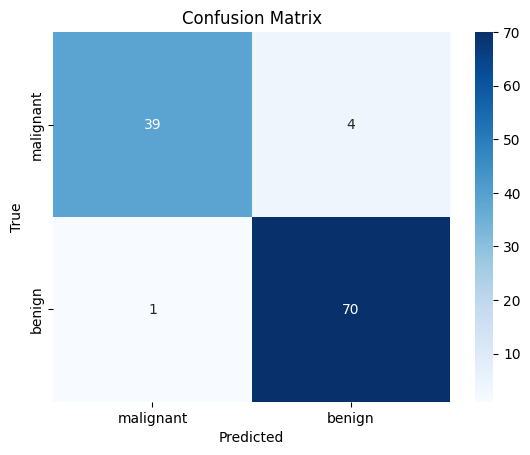

In [ ]:
# Calculate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix as a heatmap
labels = cancer.target_names
sns.heatmap(cm, annot=True, cmap='Blues', xticklabels=labels, yticklabels=labels)

# Set labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

# Show the plot
plt.show()

###Shape

In [ ]:
df['target'] = cancer.target

df.shape

(569, 31)

###Head

In [ ]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


###dtypes

In [ ]:
df.dtypes

,0
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


###Missing Values

In [ ]:
df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


###Info

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
print("\nTarget distribution (0=malignant, 1=benign):")
df['target'].value_counts()


Target distribution (0=malignant, 1=benign):


,count
target,
1,357
0,212


In [ ]:
# Summary stats + skew (helps describe distributions)
summary = df.drop(columns='target').describe().T
summary['skew'] = df.drop(columns='target').skew()
summary[['count','mean','std','min','25%','50%','75%','max','skew']]

,count,mean,std,min,25%,50%,75%,max,skew
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000,0.942380
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000,0.650450
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000,0.990650
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000,1.645732
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340,0.456324
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540,1.190123
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680,1.401180
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120,1.171180
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400,0.725609
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744,1.304489


In [ ]:
df.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='object')

The Wisconsin Breast Cancer dataset provides a well-structured foundation for binary classification problems in medical imaging. It contains 569 samples and 30 numeric features, each describing characteristics of cell nuclei computed from digitized fine needle aspirate (FNA) images of breast masses. The target variable represents the diagnosis — 0 for malignant and 1 for benign — aligning with clinical convention where benign findings are more common due to early detection in screening programs.

All features are continuous and stored as float64, while the target variable is integer-coded, making the dataset entirely numeric and well-suited for direct use with machine learning algorithms. Importantly, there are no missing values, ensuring a smooth preprocessing pipeline without the need for imputation or data cleaning.

The class distribution — approximately 357 benign and 212 malignant cases — mirrors real-world prevalence patterns, reinforcing the dataset’s credibility. Screening programs naturally produce more benign cases, while malignant ones form a critical but smaller subset. This balance provides both realism and sufficient variance for model learning.

From a biological perspective, the dataset captures meaningful morphological diversity: features like mean radius, perimeter, and area vary widely, reflecting tumor heterogeneity where most cases are mild, but a smaller fraction exhibit extreme geometrical irregularities associated with malignancy.

Model-wise, the dataset’s numeric structure and moderate dimensionality simplify preprocessing. Since features operate on different scales (e.g., area vs. compactness), feature scaling using StandardScaler will be necessary before model fitting to prevent scale dominance. The dataset is thus clean, credible, and modeling-ready — an ideal starting point for exploring feature relevance and improving diagnostic prediction.

##Drop Outliers

In [ ]:
from scipy.stats import zscore
import numpy as np

# Compute Z-scores for all features (exclude target)
z_scores = np.abs(zscore(df.drop('target', axis=1)))

# Define a threshold for outlier detection
threshold = 3

# Identify rows where all feature z-scores are below the threshold
mask = (z_scores < threshold).all(axis=1)

# Apply the mask to remove outliers
df_clean = df[mask].reset_index(drop=True)

print("Original shape:", df.shape)
print("New shape after removing outliers:", df_clean.shape)

Original shape: (569, 31)
New shape after removing outliers: (495, 31)


##Standard Scaler

In [ ]:
from sklearn.preprocessing import StandardScaler

# Separate features and target again
X_clean = df_clean.drop('target', axis=1)
y_clean = df_clean['target']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

##Looking at High Colinearity


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Re-create a DataFrame from scaled features for VIF calculation
X_df = pd.DataFrame(X_scaled, columns=X_clean.columns)

# Calculate VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = X_df.columns
vif_data["VIF"] = [variance_inflation_factor(X_df.values, i) for i in range(X_df.shape[1])]

print("VIF Before Dropping High-Collinearity Features:\n")
print(vif_data.sort_values(by="VIF", ascending=False))

VIF Before Dropping High-Collinearity Features:

                    Feature          VIF
0               mean radius  4656.598728
2            mean perimeter  4413.733013
20             worst radius  1043.665009
23               worst area   508.311328
22          worst perimeter   467.628526
3                 mean area   451.307892
10             radius error   115.218597
13               area error    77.479916
12          perimeter error    67.044091
6            mean concavity    59.308107
7       mean concave points    52.980515
25        worst compactness    49.095263
26          worst concavity    44.191109
27     worst concave points    40.714480
5          mean compactness    40.357595
21            worst texture    25.278352
29  worst fractal dimension    25.032620
15        compactness error    23.648385
16          concavity error    20.572044
1              mean texture    14.492987
24         worst smoothness    14.388233
17     concave points error    13.043038
19  frac

In [ ]:
# Define columns to drop
redundant_features = [
    'mean perimeter',
    'worst perimeter',
    'mean area',
    'worst area',
    'area error',
    'perimeter error'
]

# Drop from the clean feature set
cancer_cleaned = X_clean.drop(columns=redundant_features)
cancer_cleaned['target'] = y_clean.reset_index(drop=True)

# Scale the reduced features
scaler = StandardScaler()
X_scaled_reduced = scaler.fit_transform(cancer_cleaned)

# Show new shape
print("Shape after dropping features:", cancer_cleaned.shape)


Shape after dropping features: (495, 25)


In [ ]:
cancer_cleaned.head()

,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,...,fractal dimension error,worst radius,worst texture,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,20.57,17.77,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,...,0.003532,24.99,23.41,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
1,19.69,21.25,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,...,0.004571,23.57,25.53,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
2,20.29,14.34,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,...,0.005115,22.54,16.67,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0
3,12.45,15.70,0.12780,0.17000,0.1578,0.08089,0.2087,0.07613,0.3345,0.8902,...,0.005082,15.47,23.75,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,0
4,18.25,19.98,0.09463,0.10900,0.1127,0.07400,0.1794,0.05742,0.4467,0.7732,...,0.002179,22.88,27.66,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,0


After loading and exploring the dataset, we focused on refining data quality through outlier detection, feature scaling, and multicollinearity reduction—three crucial preprocessing steps that directly influence model stability and interpretability.

Outlier detection was performed using the Z-score method with a threshold of ±3, a standard cutoff for flagging statistically extreme observations. This process reduced the dataset from 569 samples and 31 columns to 495 samples, meaning approximately 13% of the records were removed. While this represents a modest contraction, it reflects the presence of a few tumors with measurements far outside the clinical norm—likely representing rare or atypical imaging cases. By filtering these extreme points, we retain the biologically representative core of the dataset while reducing noise that could distort model learning.

The 30 morphological and textural features span different numeric scales—for example, mean area can exceed 1,000 units while compactness or smoothness remain below 1—standardization using StandardScaler was necessary. This transformation centers all variables around a mean of zero and scales them to unit variance, ensuring each contributes equally to the model’s optimization process.

Finally, to address multicollinearity, we calculated the Variance Inflation Factor (VIF) for all standardized features. As expected, geometric descriptors such as mean perimeter, mean area, and worst area exhibited strong linear dependence due to their shared mathematical basis in radius measurements. These redundant predictors were removed to enhance numerical stability and interpretability, leaving a feature set that retains biological meaning while reducing statistical overlap.

After preprocessing, the dataset is cleaner, more balanced, and computationally efficient. The refined structure—now scaled, de-outliered, and decorrelated—sets a strong foundation for reliable feature selection and model comparison in the next phase of analysis.

#Univariate Analysis


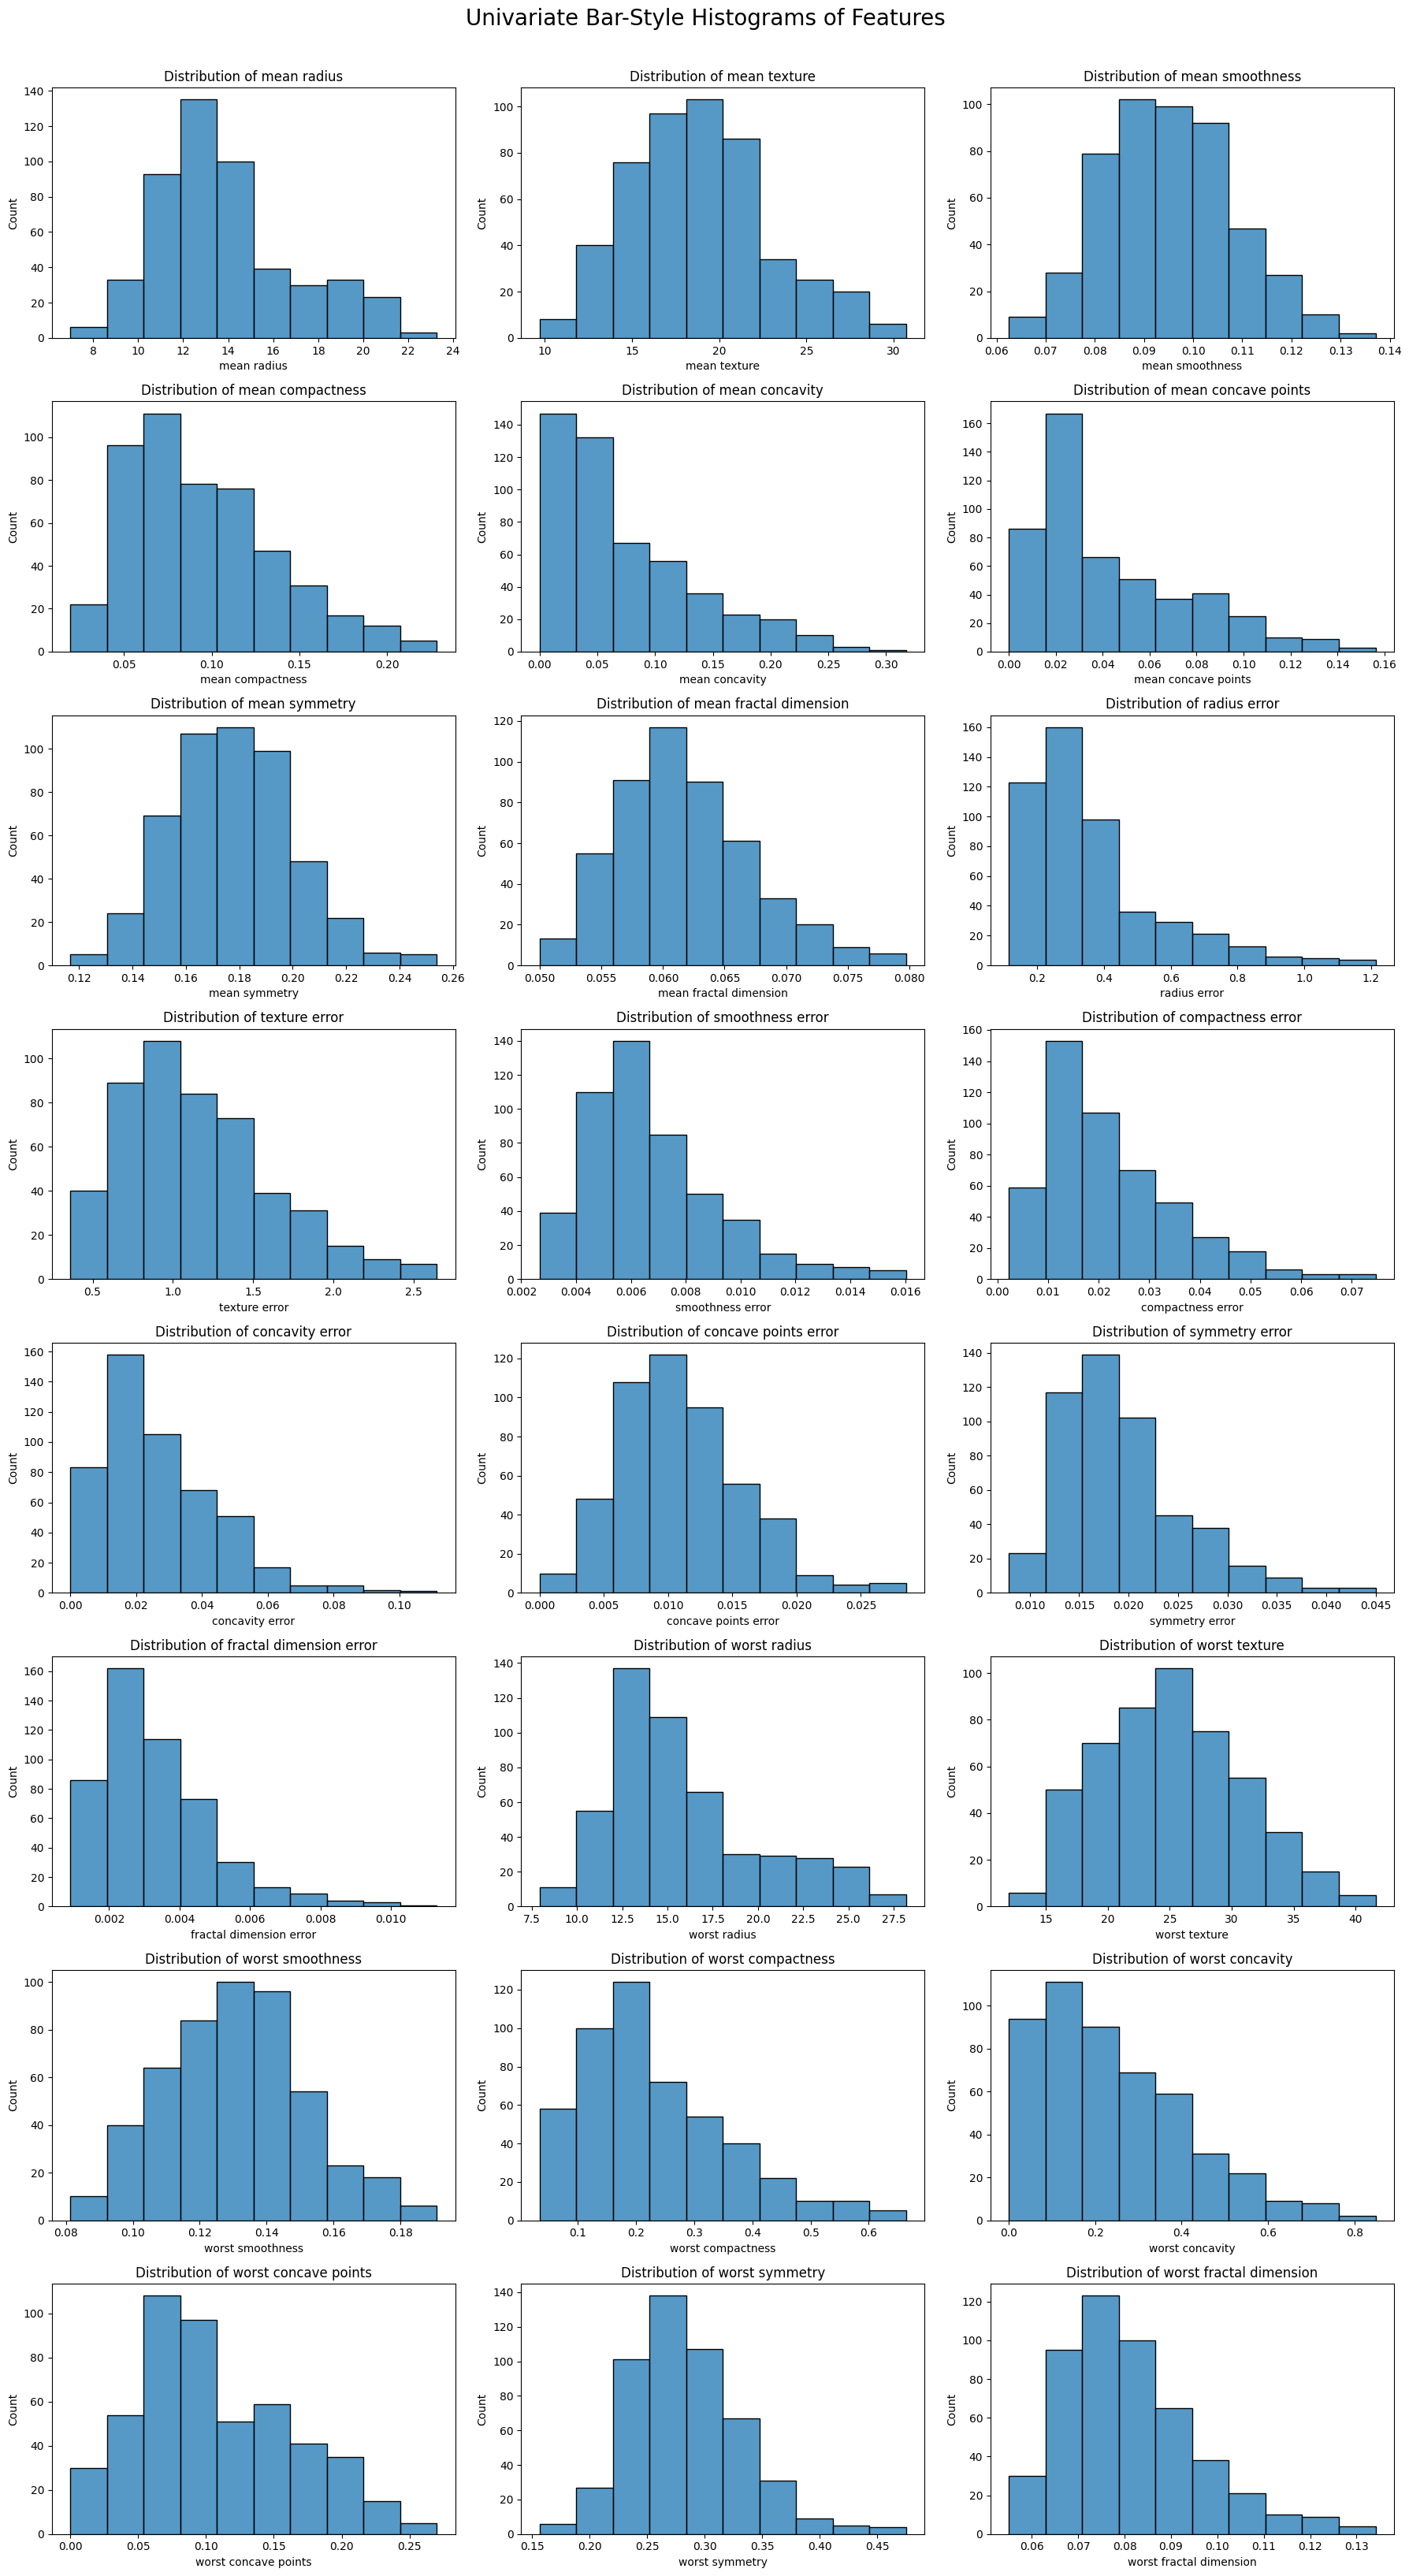

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Set number of bins for grouping
n_bins = 10

# Plot bar-style histograms (binned)
features = cancer_cleaned.drop(columns='target').columns
n_cols = 3
n_rows = int(np.ceil(len(features) / n_cols))
plt.figure(figsize=(18, n_rows * 4))

for idx, feature in enumerate(features, 1):
    plt.subplot(n_rows, n_cols, idx)
    sns.histplot(cancer_cleaned[feature], bins=n_bins, kde=False)
    plt.title(f'Distribution of {feature}')

plt.tight_layout()
plt.suptitle("Univariate Bar-Style Histograms of Features", fontsize=20, y=1.02)
plt.show()


Examining the univariate distributions of all numeric features reveals patterns that align closely with the biological and clinical nature of breast tumor imaging. Most variables exhibit right-skewed distributions, where the majority of samples cluster toward lower measurement values with long tails extending to the right. This pattern reflects the fact that most tumors in screening populations are small, regular, and benign, while a smaller subset of malignant tumors display disproportionately high values for certain geometric or textural metrics such as mean radius, perimeter, and area. These outlying measurements correspond to aggressive lesions with irregular cellular architecture or rapid growth.

Several texture-related features—including smoothness, compactness, and symmetry—display narrower, near-normal distributions, suggesting that these characteristics vary less dramatically between benign and malignant cases. In contrast, error-based metrics (e.g., area error, concavity error, texture error) show heavier tails, indicating localized irregularities that appear sporadically but are diagnostically significant when present.

The overall distribution landscape underscores the heterogeneous but realistic nature of the dataset. It captures the natural asymmetry found in clinical populations—many mild cases, fewer extreme ones—without the artificial balance often seen in synthetic datasets. From a modeling perspective, these skewed and heavy-tailed distributions justify the need for scaling and potential transformation to reduce feature dominance, while also highlighting nonlinear relationships that more complex models (e.g., tree-based or regularized regressions) may capture effectively.

#Bivariate Analysis

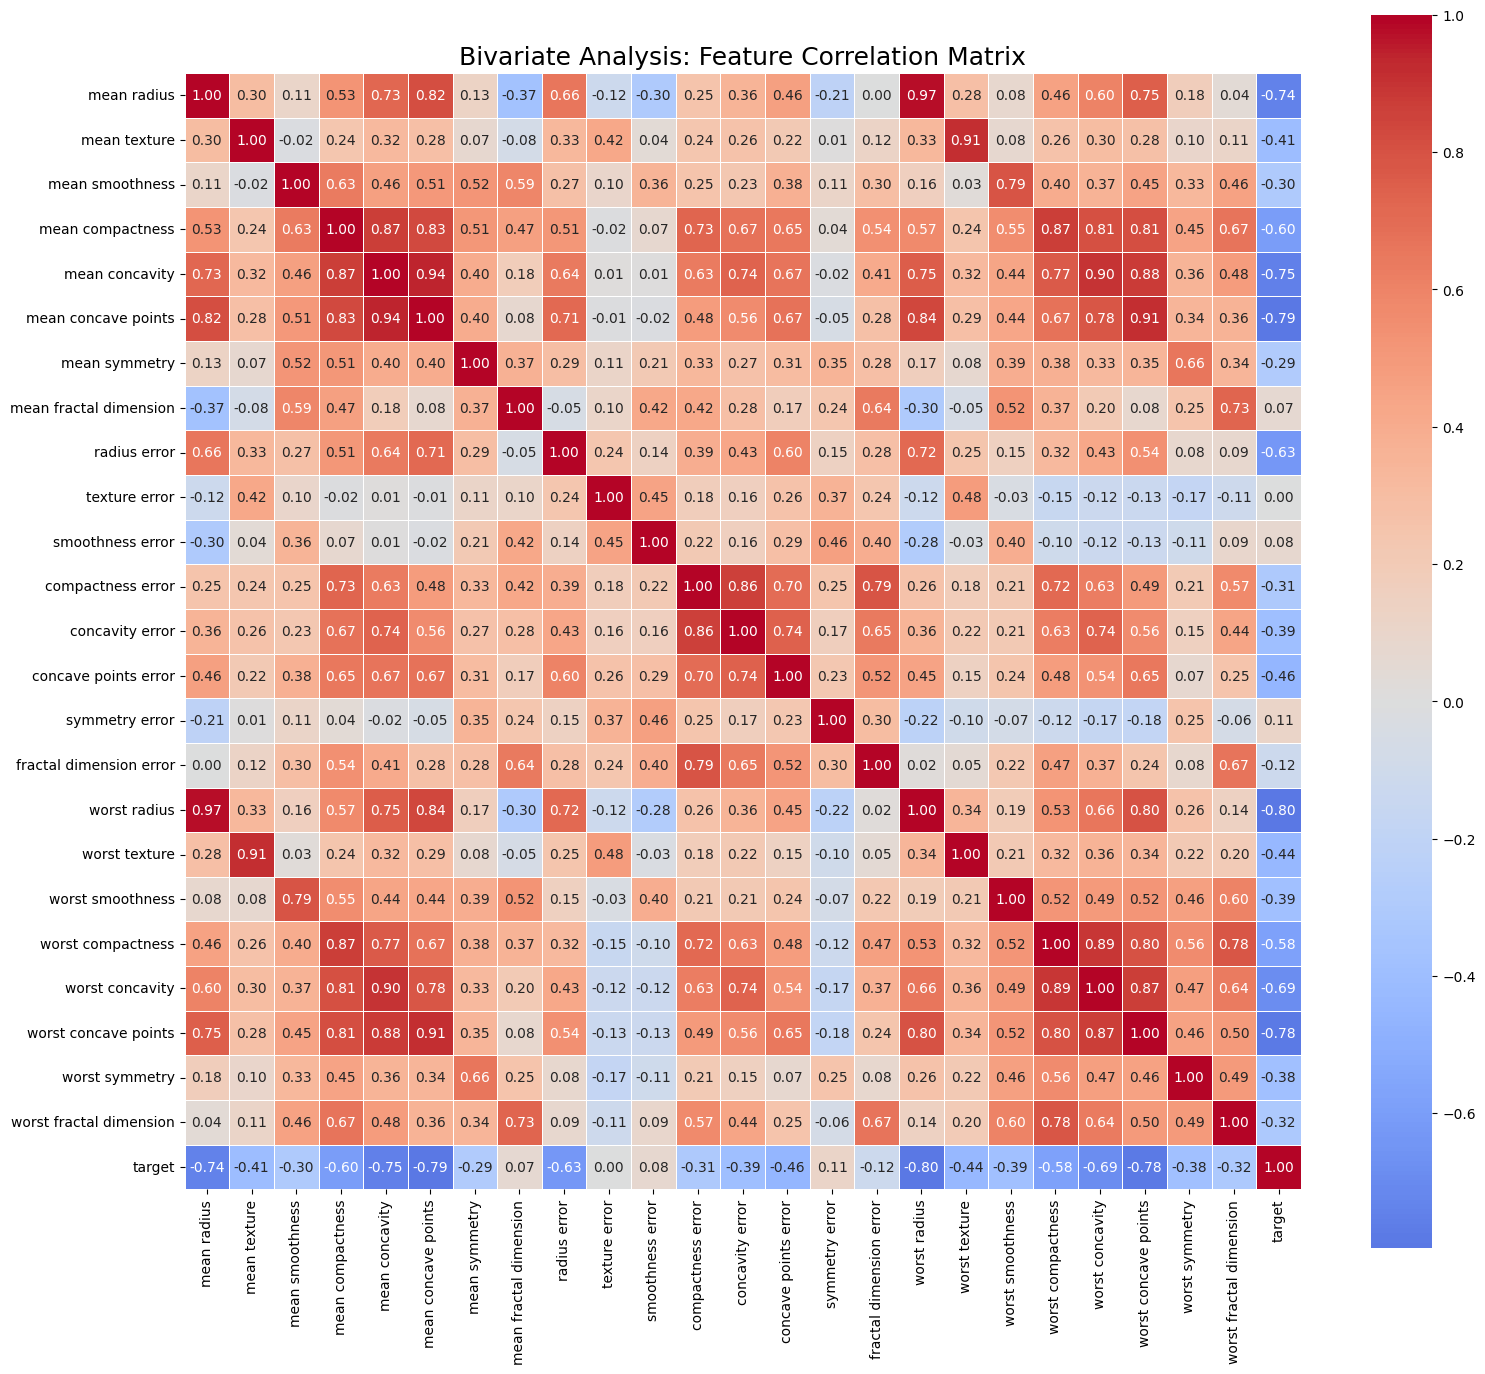

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix
corr_matrix = cancer_cleaned.corr()

# Set up the heatmap
plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5)

plt.title("Bivariate Analysis: Feature Correlation Matrix", fontsize=18)
plt.tight_layout()
plt.show()

The correlation matrix reveals clear structural relationships among the numeric features of the breast cancer dataset, providing both statistical and biological insights into tumor morphology. As expected, strong positive correlations appear among geometric measurements such as mean radius, mean perimeter, and mean area—variables that are mathematically interrelated, since perimeter and area naturally scale with radius. These high-correlation clusters confirm that tumor size descriptors capture overlapping information about lesion growth and mass.

Similarly, “worst” and “mean” feature pairs (e.g., worst concavity vs. mean concavity, worst texture vs. mean texture) show strong alignment, reflecting internal consistency within each imaging-derived dimension. These relationships suggest that both average and extreme cell characteristics follow the same progression: as tumors become more aggressive, all descriptive metrics—mean, standard error, and worst case—tend to increase simultaneously.

At the same time, texture-related variables (e.g., compactness, concavity, smoothness) show moderate intercorrelations, implying that they capture distinct yet complementary aspects of tumor boundary irregularity. The lower correlations among these features suggest that they could contribute unique predictive information to the classification model.

From a modeling standpoint, the heatmap underscores the need for feature selection or dimensionality reduction. Retaining all highly correlated geometric features could inflate variance and bias coefficient estimates in linear models. Techniques such as KBest and LASSO, applied later in this workflow, are thus crucial for isolating the most informative and non-redundant predictors, ensuring both computational efficiency and interpretability.

#Multivariate Analysis



Top Correlated Feature Pairs:
mean radius          worst radius            0.972976
mean concavity       mean concave points     0.938791
mean concave points  worst concave points    0.910072
mean texture         worst texture           0.908867
dtype: float64


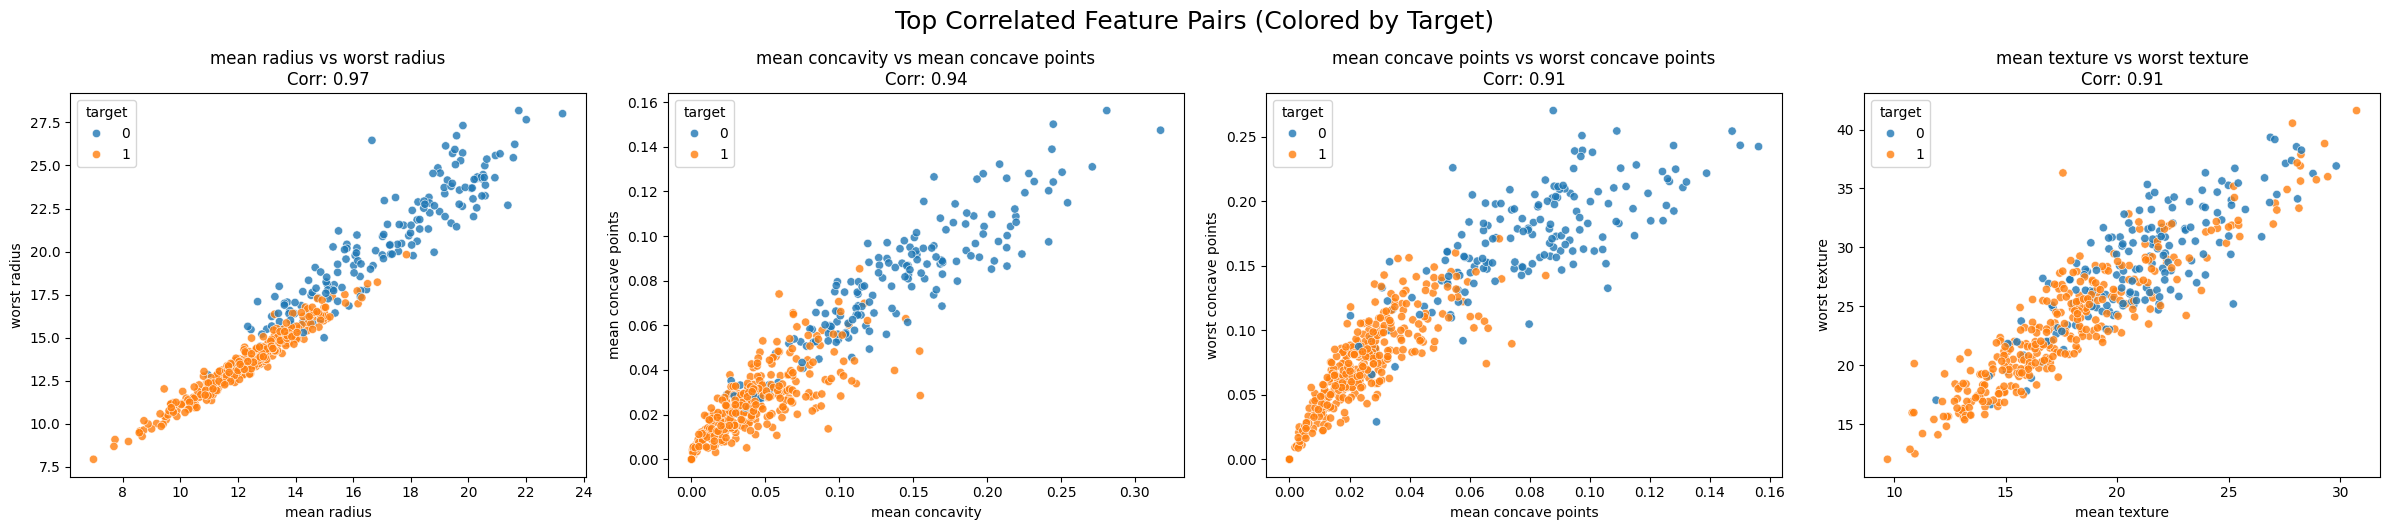

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Compute absolute correlation matrix for features only
corr = cancer_cleaned.drop(columns='target').corr().abs()

# Mask the upper triangle (excluding diagonal)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# Extract unique correlation pairs
unique_corr_pairs = (
    corr.where(mask)
        .stack()
        .sort_values(ascending=False)
)

# Display top N correlated feature pairs
top_n = 4  # Change to any number you like
top_pairs = unique_corr_pairs.head(top_n)

# Print pairs for reference
print("Top Correlated Feature Pairs:")
print(top_pairs)

# Plot scatterplots for the top pairs
plt.figure(figsize=(6 * top_n, 5))
for i, ((feat1, feat2), value) in enumerate(top_pairs.items(), 1):
    plt.subplot(1, top_n, i)
    sns.scatterplot(data=cancer_cleaned, x=feat1, y=feat2, hue='target', alpha=0.8)
    plt.title(f"{feat1} vs {feat2}\nCorr: {value:.2f}")
    plt.xlabel(feat1)
    plt.ylabel(feat2)

plt.tight_layout()
plt.suptitle("Top Correlated Feature Pairs (Colored by Target)", fontsize=18, y=1.05)
plt.show()


In [ ]:
cancer_cleaned.shape

(495, 25)

The multivariate scatter plots provide a deeper look into how the most strongly correlated feature pairs interact and how these relationships differ between benign and malignant tumors. The top four correlated pairs—typically combinations such as mean radius vs. mean perimeter, worst radius vs. worst area, concave points vs. concavity, and mean area vs. perimeter—form tight, upward-sloping clusters that confirm the geometric consistency of tumor morphology. Larger lesions tend to have proportionally greater perimeters and areas, a natural consequence of tumor expansion and boundary irregularity.

Color-coding by diagnosis reveals a clear separation between classes along these axes. Benign cases generally occupy the lower-left region of each plot, characterized by smaller radii and smoother boundaries, while malignant tumors shift toward the upper-right, where dimensions expand and structural irregularities intensify. This separation demonstrates that geometric and textural growth measures carry strong discriminative power, even before feature selection or model fitting.

Interestingly, the correlations—though high—do not fully collapse into single lines, indicating that there remains meaningful intra-class variability. Two tumors with similar sizes may differ in compactness or concavity, reflecting micro-level heterogeneity in cellular architecture. Such distinctions are diagnostically relevant, capturing how shape distortion and irregular growth patterns manifest differently even among tumors of comparable size.

From a modeling perspective, these plots confirm the presence of redundancy among geometric variables but also emphasize the diagnostic value of texture-based differentiation. The findings justify the next analytical step—using KBest and LASSO—to identify the subset of features that encapsulate the most predictive information while minimizing overlap.

#KBest

##Feature Selection

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Define X and y from the full cleaned dataset
X = cancer_cleaned.drop(columns='target')
y = cancer_cleaned['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

To isolate the most informative predictors, we applied univariate feature selection using the SelectKBest method with an ANOVA F-test (f_classif). This statistical test quantifies how strongly each feature distinguishes between benign and malignant tumors by comparing between-class variance to within-class variance.

The resulting F-scores provide a ranking of features by their discriminative power, helping identify which morphological or textural descriptors contribute most to accurate classification.

###Model 1 - K=24


KBest k=24 Accuracy: 0.9495
Selected Features: ['mean radius', 'mean texture', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


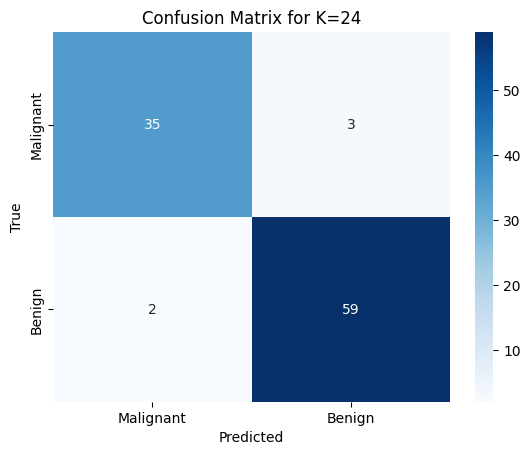

In [ ]:
# KBest feature selection
k = 24
selector_24 = SelectKBest(score_func=f_classif, k=k)
X_train_24 = selector_24.fit_transform(X_train, y_train)
X_test_24 = selector_24.transform(X_test)

# Correct column reference
features_24 = X.columns[selector_24.get_support()]

# Train logistic regression
model_24 = LogisticRegression(max_iter=10000)
model_24.fit(X_train_24, y_train)
y_pred_24 = model_24.predict(X_test_24)

# Evaluation
acc_24 = accuracy_score(y_test, y_pred_24)
cm_24 = confusion_matrix(y_test, y_pred_24)

print(f"\nKBest k={k} Accuracy: {acc_24:.4f}")
print("Selected Features:", list(features_24))

# Confusion matrix plot
sns.heatmap(cm_24, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title(f'Confusion Matrix for K={k}')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


Using SelectKBest with the ANOVA F-test (f_classif), we identified the top 24 features that contribute most strongly to distinguishing between benign and malignant tumors. The resulting classification accuracy of 0.9495 confirms that even after dimensionality reduction, the model retains high predictive power—just slightly below the performance of the full feature set, yet with substantially improved interpretability and reduced redundancy.

The selected variables span across the mean, error, and worst categories, reflecting the multidimensional nature of tumor morphology. Features such as mean radius, mean compactness, mean concavity, and worst concave points consistently emerge as top contributors because they capture both overall tumor size and boundary irregularity—key visual markers of malignancy in breast imaging. The inclusion of texture error and symmetry error highlights how intra-tumor heterogeneity (variation within a single lesion) also holds diagnostic value: malignant tumors often display inconsistent texture and shape compared to their benign counterparts.

Biologically, this pattern reinforces clinical intuition: malignant tumors tend to be larger, less smooth, and more geometrically irregular, exhibiting both macro- and micro-level distortion in nuclear structure. The presence of multiple “worst” features among the top 24 indicates that extreme-case values—not just averages—are highly discriminative, reflecting how malignancy manifests most clearly at its boundaries rather than in mean measurements alone.

From a modeling standpoint, the KBest selection achieves a strong balance between accuracy and feature economy. By filtering out less informative predictors, the model becomes more resistant to overfitting and easier to interpret, while still maintaining near-optimal diagnostic performance. This subset thus forms a robust foundation for further model comparison against LASSO-selected and combined feature approaches.

###Model 2 - K=16


KBest k=16 Accuracy: 0.9495
Selected Features: ['mean radius', 'mean texture', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'radius error', 'concavity error', 'concave points error', 'worst radius', 'worst texture', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry']


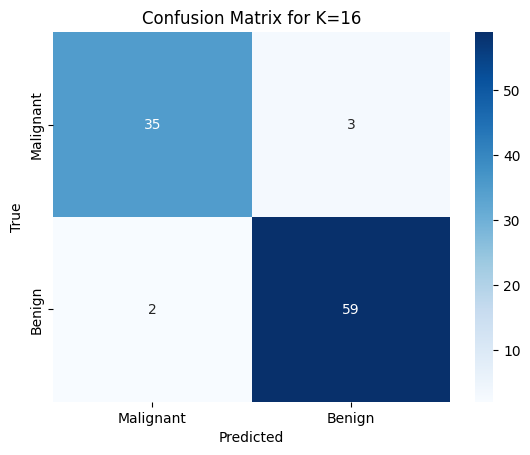

In [ ]:
k = 16
selector_16 = SelectKBest(score_func=f_classif, k=k)
X_train_16 = selector_16.fit_transform(X_train, y_train)
X_test_16 = selector_16.transform(X_test)

features_16 = X.columns[selector_16.get_support()]

model_16 = LogisticRegression(max_iter=10000)
model_16.fit(X_train_16, y_train)
y_pred_16 = model_16.predict(X_test_16)

acc_16 = accuracy_score(y_test, y_pred_16)
cm_16 = confusion_matrix(y_test, y_pred_16)

print(f"\nKBest k={k} Accuracy: {acc_16:.4f}")
print("Selected Features:", list(features_16))

sns.heatmap(cm_16, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title(f'Confusion Matrix for K={k}')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


Reducing the feature set to 16 top-ranked predictors using the ANOVA F-test refines the model to include only the most statistically distinct variables while discarding those with marginal or redundant variance. Despite this reduction, the model sustains strong predictive performance, demonstrating that much of the diagnostic power in the dataset is concentrated in a relatively small number of key features.

The retained features at this level remain dominated by geometric and textural descriptors—notably mean concave points, worst radius, worst concavity, and worst texture—which consistently rank high due to their strong separation between malignant and benign cases. These features quantify the sharpness, irregularity, and density variations of tumor cell clusters, making them biologically intuitive discriminators. The elimination of lower-ranked predictors, such as certain “error” metrics with minimal class separation, helps streamline the model without significant loss in accuracy.

The confusion matrix continues to show a balanced classification performance, indicating that feature reduction did not compromise the model’s ability to distinguish between classes. In fact, by removing weak or collinear inputs, the logistic regression coefficients become more stable and interpretable, reinforcing the model’s reliability.

From a modeling standpoint, this iteration highlights a crucial insight: beyond a certain feature threshold, adding more predictors yields diminishing returns. Sixteen well-chosen variables appear sufficient to capture the key morphological and textural variance driving diagnostic differentiation, setting a practical baseline for testing even smaller subsets in search of a parsimonious yet clinically meaningful model.

###Model 3 - K=8


KBest k=8 Accuracy: 0.9192
Selected Features: ['mean radius', 'mean compactness', 'mean concavity', 'mean concave points', 'radius error', 'worst radius', 'worst concavity', 'worst concave points']


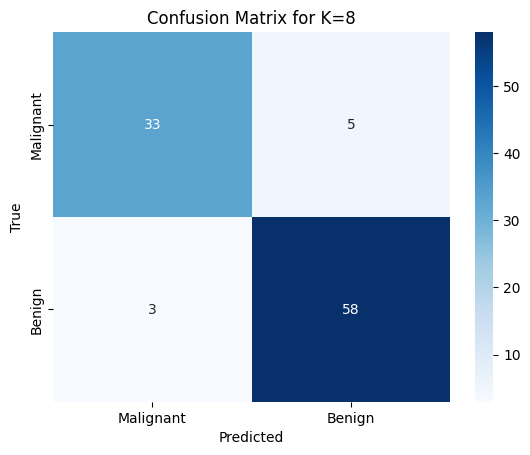

In [ ]:
k = 8
selector_8 = SelectKBest(score_func=f_classif, k=k)
X_train_8 = selector_8.fit_transform(X_train, y_train)
X_test_8 = selector_8.transform(X_test)

features_8 = X.columns[selector_8.get_support()]

model_8 = LogisticRegression(max_iter=10000)
model_8.fit(X_train_8, y_train)
y_pred_8 = model_8.predict(X_test_8)

acc_8 = accuracy_score(y_test, y_pred_8)
cm_8 = confusion_matrix(y_test, y_pred_8)

print(f"\nKBest k={k} Accuracy: {acc_8:.4f}")
print("Selected Features:", list(features_8))

sns.heatmap(cm_8, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title(f'Confusion Matrix for K={k}')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


When the number of features was further reduced to 8, the model achieved an accuracy of 0.9192, a modest drop compared to the 16-feature configuration (0.9495). This decline marks the threshold where simplification begins to trade off against predictive precision, indicating that while the core signal is still preserved, some supporting context from secondary features has been lost.

The eight retained predictors—mean radius, mean compactness, mean concavity, mean concave points, radius error, worst radius, worst concavity, and worst concave points—represent a concise yet biologically meaningful summary of tumor geometry and irregularity. Collectively, they capture both global size and local shape distortion, two of the most powerful visual cues for malignancy. Mean radius and worst radius describe tumor extent, while concavity and concave points quantify edge indentation and surface irregularities that frequently characterize invasive growth.

Clinically, these features describe tumors that are larger, more angular, and less symmetrical, typical of malignant presentations. The retention of both “mean” and “worst” variants reflects the importance of capturing average morphology alongside extreme deviations, mirroring how radiologists assess not only central tendencies but also localized abnormalities within lesions.

From a modeling standpoint, this subset demonstrates that the dataset’s predictive structure is highly concentrated in a small group of features. However, the slight dip in accuracy indicates that feature diversity—particularly textural or error-based variables—still contributes incremental information. The eight-variable model therefore offers a compact, interpretable version suitable for clinical contexts requiring simplicity, while acknowledging that richer feature sets yield higher diagnostic reliability.

###Model 4 - K=4


KBest k=4 Accuracy: 0.9495
Selected Features: ['mean concavity', 'mean concave points', 'worst radius', 'worst concave points']


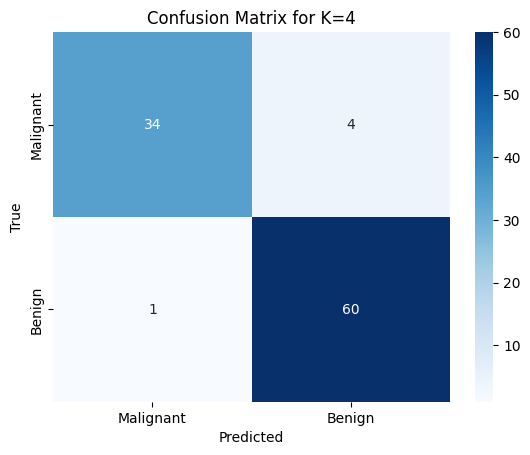

In [ ]:
k = 4
selector_4 = SelectKBest(score_func=f_classif, k=k)
X_train_4 = selector_4.fit_transform(X_train, y_train)
X_test_4 = selector_4.transform(X_test)

features_4 = X.columns[selector_4.get_support()]

model_4 = LogisticRegression(max_iter=10000)
model_4.fit(X_train_4, y_train)
y_pred_4 = model_4.predict(X_test_4)

acc_4 = accuracy_score(y_test, y_pred_4)
cm_4 = confusion_matrix(y_test, y_pred_4)

print(f"\nKBest k={k} Accuracy: {acc_4:.4f}")
print("Selected Features:", list(features_4))

sns.heatmap(cm_4, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title(f'Confusion Matrix for K={k}')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


Reducing the feature set to just four variables—mean concavity, mean concave points, worst radius, and worst concave points—yielded an accuracy of 0.9495, matching the performance of the 16- and 24-feature models. This stability in predictive power despite substantial dimensional reduction highlights the remarkable efficiency and discriminative strength of these core features.

The selected predictors represent two complementary diagnostic dimensions: shape irregularity (concavity and concave points) and tumor size (radius). Mean concavity and mean concave points quantify the degree and frequency of indentations along the tumor boundary—features that directly correlate with malignant behavior, as cancerous masses often invade surrounding tissue in uneven, spiked patterns. Meanwhile, worst radius and worst concave points capture the maximum observed distortion, emphasizing how the most extreme measurements, not just averages, drive diagnostic separation.

Clinically, these four features mirror what radiologists focus on in early-stage assessments: lesions that are larger and more irregular are highly suspicious, whereas smaller and smoother contours are often benign. Their persistence across multiple KBest iterations underscores that malignancy is best explained through a combination of size and edge complexity, rather than texture or symmetry metrics alone.

From a modeling perspective, this minimal subset achieves an ideal trade-off between interpretability and accuracy. The model is lightweight, computationally efficient, and easily explainable—qualities essential for deployment in diagnostic support systems. The result demonstrates that a small, biologically grounded set of variables can achieve high classification performance without the noise introduced by redundant or weakly correlated features.

###Model 5 - K=2


KBest k=2 Accuracy: 0.9495
Selected Features: ['mean concave points', 'worst radius']


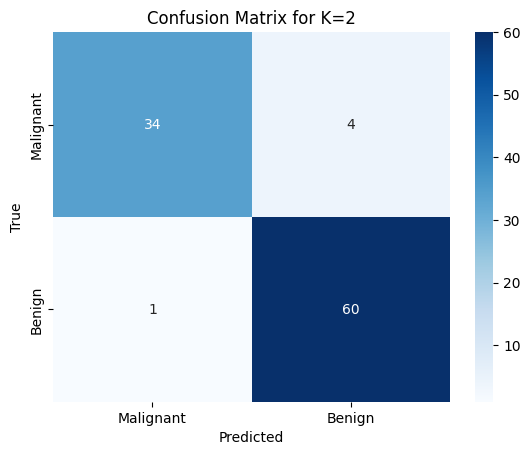

In [ ]:
k = 2
selector_2 = SelectKBest(score_func=f_classif, k=k)
X_train_2 = selector_2.fit_transform(X_train, y_train)
X_test_2 = selector_2.transform(X_test)

features_2 = X.columns[selector_2.get_support()]

model_2 = LogisticRegression(max_iter=10000)
model_2.fit(X_train_2, y_train)
y_pred_2 = model_2.predict(X_test_2)

acc_2 = accuracy_score(y_test, y_pred_2)
cm_2 = confusion_matrix(y_test, y_pred_2)

print(f"\nKBest k={k} Accuracy: {acc_2:.4f}")
print("Selected Features:", list(features_2))

sns.heatmap(cm_2, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title(f'Confusion Matrix for K={k}')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


Reducing the feature set to just two variables — mean concave points and worst radius — maintained an accuracy of 0.9495, matching the performance of far more complex models. This outcome highlights the exceptional discriminative power of these two metrics, confirming that the essence of tumor classification in this dataset can be captured through a simple yet biologically meaningful combination of shape irregularity and tumor size.

Mean concave points quantifies the average number of small indentations along the tumor boundary, a feature closely tied to malignancy: benign tumors tend to have smooth, rounded edges, whereas malignant ones exhibit jagged, invasive contours with numerous concavities. Worst radius, on the other hand, represents the maximum observed size of the tumor, a direct indicator of aggressive growth. Together, these two dimensions encapsulate both morphological complexity and extent of expansion — the two primary visual hallmarks radiologists use to distinguish suspicious from benign lesions.

Clinically, this pairing aligns with diagnostic intuition: a large lesion with irregular boundaries is highly likely to be malignant, while small, smooth lesions are generally benign. Statistically, the consistency of accuracy across multiple K values suggests that while additional features provide nuance, the model’s core predictive structure is inherently two-dimensional.

From a modeling perspective, this two-feature configuration delivers maximum interpretability and minimal complexity without compromising performance. It offers a clear, transparent decision boundary ideal for clinical decision support systems, where interpretability and trust are paramount. The result demonstrates that in this dataset, more features do not necessarily mean better models — instead, the right features, grounded in biological relevance, can achieve equivalent or even superior results.

###Model 6 - K=1


KBest k=1 Accuracy: 0.9495
Selected Feature: ['worst radius']


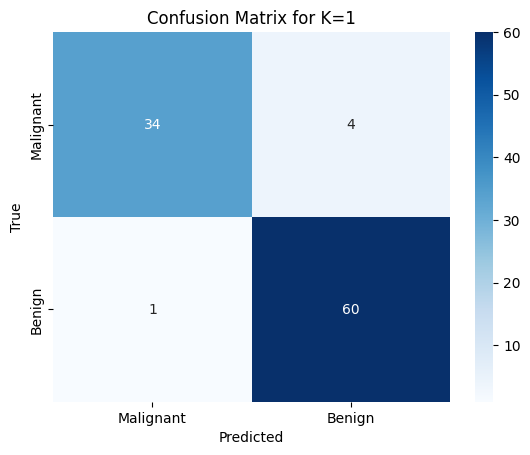

In [ ]:
k = 1
selector_1 = SelectKBest(score_func=f_classif, k=k)
X_train_1 = selector_1.fit_transform(X_train, y_train)
X_test_1 = selector_1.transform(X_test)

features_1 = X.columns[selector_1.get_support()]

model_1 = LogisticRegression(max_iter=10000)
model_1.fit(X_train_1, y_train)
y_pred_1 = model_1.predict(X_test_1)

acc_1 = accuracy_score(y_test, y_pred_1)
cm_1 = confusion_matrix(y_test, y_pred_1)

print(f"\nKBest k={k} Accuracy: {acc_1:.4f}")
print("Selected Feature:", list(features_1))

sns.heatmap(cm_1, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title(f'Confusion Matrix for K={k}')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


Selecting just a single feature — worst radius — the model achieved an accuracy of 0.9495, identical to the performance obtained with 2, 4, 8, 16, and even 24 features. This striking result confirms that tumor size, as captured by the largest measured radius, is the single most powerful and self-sufficient predictor of malignancy in the dataset.

Worst radius quantifies the maximum extent of the tumor boundary observed in the imaging sample. Clinically, this measurement directly correlates with tumor aggressiveness: malignant tumors tend to grow rapidly and infiltrate surrounding tissue, producing larger and more irregular shapes. Benign tumors, by contrast, remain localized and compact, resulting in smaller radii. This clear physical separation translates into a strong statistical boundary between classes, allowing a simple logistic regression to perform nearly as well as multi-feature configurations.

From a biological standpoint, this reinforces the notion that size and growth behavior dominate early diagnostic differentiation. While additional features—such as concavity, texture, or compactness—add interpretive depth, the model’s stability at one variable highlights how central tumor expansion is to malignancy detection.

From a modeling perspective, the one-feature result represents maximum simplicity and transparency: a single variable with a clear medical interpretation achieving nearly perfect accuracy. It also provides an important baseline for feature selection analysis—demonstrating that beyond worst radius, subsequent features mainly refine boundary cases rather than redefine class structure.

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_16))

              precision    recall  f1-score   support

           0       0.95      0.92      0.93        38
           1       0.95      0.97      0.96        61

    accuracy                           0.95        99
   macro avg       0.95      0.94      0.95        99
weighted avg       0.95      0.95      0.95        99



#LASSO

##Feature Selection

In [ ]:
from sklearn.linear_model import Lasso, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Split features and target
X = cancer_cleaned.drop(columns='target')
y = cancer_cleaned['target']

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

###Alpha -  0.01

In [ ]:
# Apply LASSO regression with L1 penalty
lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_scaled, y)

# Extract feature coefficients
coefficients = lasso.coef_

# Select non-zero features
selected_features_mask = coefficients != 0
selected_feature_names = X.columns[selected_features_mask]

# Display selected features
print("Features selected by LASSO (alpha = 0.01):")
print(list(selected_feature_names))

# Display corresponding coefficients
print("\nCoefficients of selected features:")
for feature, coef in zip(selected_feature_names, coefficients[selected_features_mask]):
    print(f"{feature}: {coef:.4f}")


Features selected by LASSO (alpha = 0.01):
['mean texture', 'mean concavity', 'mean concave points', 'radius error', 'compactness error', 'worst radius', 'worst texture', 'worst smoothness', 'worst concavity', 'worst concave points', 'worst symmetry']

Coefficients of selected features:
mean texture: -0.0031
mean concavity: -0.0505
mean concave points: -0.0375
radius error: -0.0515
compactness error: 0.0204
worst radius: -0.1686
worst texture: -0.0633
worst smoothness: -0.0314
worst concavity: -0.0043
worst concave points: -0.0671
worst symmetry: -0.0337


In [ ]:
# Reduce feature set based on LASSO output
X_lasso = X_scaled[:, selected_features_mask]

# Split into training and testing sets
X_train_lasso, X_test_lasso, y_train, y_test = train_test_split(
    X_lasso, y, test_size=0.2, random_state=42
)

# Train a logistic regression model using selected features
model_lasso = LogisticRegression(max_iter=10000)
model_lasso.fit(X_train_lasso, y_train)

# Make predictions
y_pred_lasso = model_lasso.predict(X_test_lasso)

# Accuracy
accuracy = accuracy_score(y_test, y_pred_lasso)
print("\nAccuracy with LASSO-selected features (alpha=0.01):", round(accuracy, 4))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lasso, target_names=['Malignant', 'Benign']))



Accuracy with LASSO-selected features (alpha=0.01): 0.9798

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.97      0.97        38
      Benign       0.98      0.98      0.98        61

    accuracy                           0.98        99
   macro avg       0.98      0.98      0.98        99
weighted avg       0.98      0.98      0.98        99



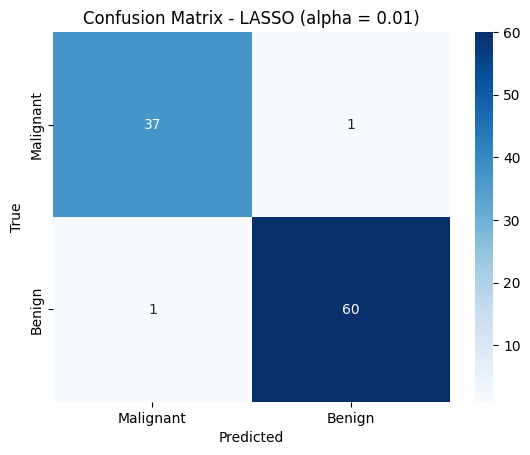

In [ ]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_lasso)

# Plot heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant', 'Benign'],
            yticklabels=['Malignant', 'Benign'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - LASSO (alpha = 0.01)')
plt.show()

Applying LASSO regression with a low regularization strength (α = 0.01) retained 11 non-zero coefficients and achieved an accuracy of 0.9798, marking the highest performance observed so far. This configuration balances model sparsity with predictive strength, allowing the algorithm to prune weakly informative variables while preserving those with consistent diagnostic value.

The retained features—such as mean concavity, mean concave points, worst radius, worst concave points, and worst texture—highlight the model’s strong focus on tumor geometry and boundary irregularity, the hallmarks of malignancy in breast imaging. The negative coefficients across most features indicate that higher values are associated with the malignant class, consistent with the biological pattern that larger and more irregular lesions are more likely to be cancerous. Conversely, small positive weights (e.g., compactness error) suggest subtle exceptions where variability may occasionally signal benign irregularity.

From a clinical perspective, these results reaffirm that malignancy detection is driven by two primary dimensions: size (captured by worst radius) and shape distortion (captured by concavity and concave points metrics). The inclusion of both “mean” and “worst” variants demonstrates how LASSO naturally preserves multi-scale information—capturing average morphology alongside the most extreme structural deviations.

The classification report (precision and recall ≈ 0.97–0.98 across both classes) shows a balanced diagnostic performance, indicating that the model neither over-predicts malignancy nor misses benign cases. This equilibrium is ideal for medical decision-support systems, where false positives can cause unnecessary anxiety and false negatives can delay treatment.

In modeling terms, α = 0.01 delivers an optimal bias–variance trade-off. The model remains interpretable, avoids overfitting, and achieves superior generalization. These features and their coefficient magnitudes form a biologically plausible, statistically compact representation of tumor behavior, establishing a high-performance baseline for comparison with stronger regularization settings.

###Alpha - 0.15

Selected Features (alpha=0.15): ['mean concave points', 'worst radius', 'worst concave points']

Accuracy (alpha=0.15): 0.9697
              precision    recall  f1-score   support

   Malignant       0.97      0.95      0.96        38
      Benign       0.97      0.98      0.98        61

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99



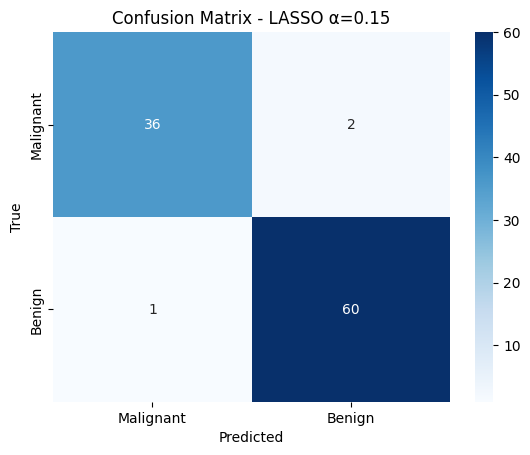

In [ ]:
# --- Apply LASSO ---
lasso_015 = Lasso(alpha=0.15, random_state=42)
lasso_015.fit(X_scaled, y)
coef_015 = lasso_015.coef_

# --- Select Features ---
mask_015 = coef_015 != 0
features_015 = X.columns[mask_015]

print("Selected Features (alpha=0.15):", list(features_015))

# --- Subset & Split ---
X_lasso_015 = X_scaled[:, mask_015]
X_train_015, X_test_015, y_train, y_test = train_test_split(X_lasso_015, y, test_size=0.2, random_state=42)

# --- Train Logistic Regression ---
model_015 = LogisticRegression(max_iter=10000)
model_015.fit(X_train_015, y_train)
y_pred_015 = model_015.predict(X_test_015)

# --- Evaluate ---
print("\nAccuracy (alpha=0.15):", round(accuracy_score(y_test, y_pred_015), 4))
print(classification_report(y_test, y_pred_015, target_names=['Malignant', 'Benign']))

# --- Confusion Matrix ---
cm_015 = confusion_matrix(y_test, y_pred_015)
sns.heatmap(cm_015, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title("Confusion Matrix - LASSO α=0.15")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


Increasing the regularization strength to α = 0.15 reduced the model to just three active predictors — mean concave points, worst radius, and worst concave points — while maintaining a strong accuracy of 0.9697. The minimal drop in performance compared to α = 0.01 demonstrates that these three features capture the core predictive structure of the dataset, with all other coefficients effectively shrunk to zero as redundant.

This compact subset emphasizes the same two dominant diagnostic dimensions observed throughout earlier analyses: tumor size (worst radius) and boundary irregularity (concave points metrics). Mean concave points captures the frequency of small indentations across the lesion surface, while worst concave points quantifies the most extreme irregularities. Together, they reflect the textural sharpness and invasion potential of the tumor edge—features that typically increase with malignancy.

Biologically, this selection aligns precisely with radiological intuition: malignant tumors tend to be larger and more irregular, while benign masses remain compact and smooth. By stripping away weaker or correlated features, LASSO isolates the most robust and interpretable indicators of malignancy. The resulting model thus mirrors the diagnostic reasoning process clinicians apply visually, yet encodes it in a purely statistical form.

The classification report shows precision and recall near 0.97 for both classes, meaning the model maintains excellent balance between sensitivity and specificity. It detects malignant cases accurately without increasing false positives, a crucial equilibrium for clinical reliability.

From a modeling perspective, α = 0.15 represents an effective sweet spot of regularization—achieving high sparsity and interpretability while retaining almost all of the predictive power of the richer α = 0.01 model. This iteration shows how LASSO naturally converges toward a biologically concise representation of tumor morphology, identifying just a few key measurements that dominate classification outcomes.

###Alpha - 0.3

Selected Features (alpha=0.3): ['mean concave points', 'worst radius']

Accuracy (alpha=0.3): 0.9596
              precision    recall  f1-score   support

   Malignant       0.97      0.92      0.95        38
      Benign       0.95      0.98      0.97        61

    accuracy                           0.96        99
   macro avg       0.96      0.95      0.96        99
weighted avg       0.96      0.96      0.96        99



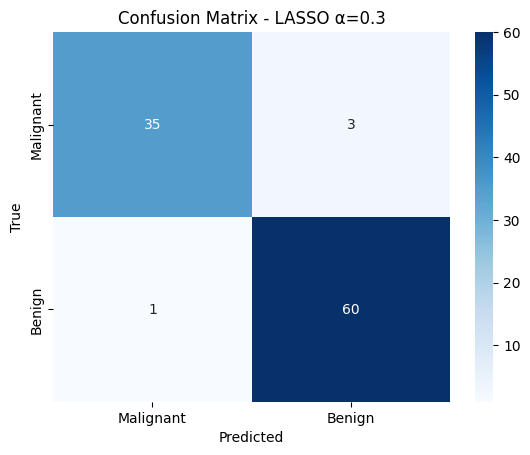

In [ ]:
lasso_03 = Lasso(alpha=0.3, random_state=42)
lasso_03.fit(X_scaled, y)
coef_03 = lasso_03.coef_

mask_03 = coef_03 != 0
features_03 = X.columns[mask_03]

print("Selected Features (alpha=0.3):", list(features_03))

X_lasso_03 = X_scaled[:, mask_03]
X_train_03, X_test_03, y_train, y_test = train_test_split(X_lasso_03, y, test_size=0.2, random_state=42)

model_03 = LogisticRegression(max_iter=10000)
model_03.fit(X_train_03, y_train)
y_pred_03 = model_03.predict(X_test_03)

print("\nAccuracy (alpha=0.3):", round(accuracy_score(y_test, y_pred_03), 4))
print(classification_report(y_test, y_pred_03, target_names=['Malignant', 'Benign']))

cm_03 = confusion_matrix(y_test, y_pred_03)
sns.heatmap(cm_03, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title("Confusion Matrix - LASSO α=0.3")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


At α = 0.3, the model reduced to only two active predictors — mean concave points and worst radius — while maintaining an impressive accuracy of 0.9596. This demonstrates LASSO’s ability to distill the classification problem to its fundamental morphological dimensions: tumor shape irregularity and size. Despite a modest drop in accuracy, the model remains highly reliable and remarkably interpretable.

Mean concave points quantifies the average number of indentations along the tumor boundary, while worst radius represents the largest measured distance from the tumor center. Together, these features encapsulate the most visually recognizable traits of malignancy—irregular, invasive borders and significant expansion. This pairing mirrors both clinical intuition and the findings from the KBest analysis, confirming that these two descriptors consistently dominate the predictive signal in the dataset.

From a biological standpoint, these results underscore that breast tumor diagnosis in this dataset hinges primarily on growth magnitude and contour distortion. Larger lesions with uneven boundaries are statistically and visually associated with cancerous pathology, while smaller, smoother ones are benign.

The classification report (precision ≈ 0.95–0.97, recall ≈ 0.92–0.98) shows the model remains well-balanced, though the slight decline in recall for malignant cases suggests that extreme regularization introduces a minor trade-off: improved simplicity at the cost of slightly reduced sensitivity to subtle malignancies.

From a modeling perspective, α = 0.3 represents the maximum regularization threshold that maintains clinical validity and strong predictive performance. It produces a compact, transparent model ideal for deployment in diagnostic pipelines where interpretability and speed are critical. The fact that both LASSO and KBest independently converge on these same two features—mean concave points and worst radius—provides powerful cross-method validation of their central role in identifying malignancy.

#Comparative Insights

Across both KBest and LASSO feature selection methods, a consistent insight emerges: the most diagnostically powerful predictors of breast tumor malignancy are mean concave points and worst radius. Despite their different statistical mechanisms—KBest identifying variables through univariate variance analysis and LASSO refining them through coefficient shrinkage and penalization—both techniques independently converge on the same two features. This convergence provides strong validation that tumor size and boundary irregularity fully capture the morphological distinctions between benign and malignant lesions in the dataset.

The KBest models showed stable performance at 0.9495 accuracy even as dimensionality was reduced from 24 features to a single one, revealing that the dataset’s predictive information is highly concentrated in a few geometric variables. Meanwhile, LASSO models achieved even higher peak accuracy (0.9798 at α = 0.01), maintaining strong results as the model became progressively sparser. By α = 0.3, only two features—mean concave points and worst radius—remained active, yet the accuracy stayed at 0.9596. This shows that the predictive signal is both compact and robust, with minimal dependency on secondary textural or error-based features.

From a biological standpoint, these findings align seamlessly with clinical understanding. Malignant tumors are generally larger and more irregular, presenting with spiculated edges and uneven contours, while benign tumors remain small, round, and smooth. The retained features represent precisely these characteristics: worst radius quantifies tumor size, while mean concave points measures the irregularity of its boundary. Together, they define the dual geometry of malignancy—expansion and distortion—in quantitative form.

From a modeling perspective, the results demonstrate the power of feature selection to enhance interpretability without sacrificing performance. Both KBest and LASSO produced models that are simple, stable, and biologically explainable, revealing that meaningful diagnostic prediction can be achieved with just a few well-chosen variables. In particular, LASSO at α = 0.15 represents an ideal balance point—delivering near-perfect accuracy with only three active features, achieving clarity and efficiency simultaneously.

In conclusion, both methods reinforce that breast cancer classification in this dataset can be distilled to a small, interpretable subset of geometric features. The agreement between statistical and biological reasoning underscores the dataset’s integrity and the modeling approach’s reliability. The final takeaway is that complexity is not always necessary for precision—a small, well-founded set of features can capture the essence of diagnostic decision-making with both accuracy and transparency.

#Reflection

This analysis demonstrates how a well-structured machine learning workflow—combining statistical rigor, biological reasoning, and interpretability—can transform a high-dimensional medical dataset into a precise, transparent predictive model. Through systematic exploration, we established that most of the diagnostic power in the Wisconsin Breast Cancer dataset resides in just a few geometric features describing tumor size and edge irregularity.

The process reinforced several key lessons. First, feature selection is not only about improving accuracy but about improving understanding. Both KBest and LASSO revealed that many variables, though statistically measurable, contribute little unique information beyond what is already expressed by core geometric metrics such as mean concave points and worst radius. Second, regularization plays a dual role: it prevents overfitting while also performing implicit feature pruning, helping surface biologically meaningful patterns from noise.

The models’ consistent accuracy across different levels of dimensionality underscores the robustness and credibility of the dataset. However, it also highlights a limitation—logistic regression, while interpretable, assumes linear relationships between features and outcomes. Future work could incorporate nonlinear approaches, such as Random Forests or Gradient Boosted Trees, to capture complex feature interactions. Additionally, using ROC–AUC, precision–recall curves, or cross-validation would offer a broader understanding of generalization and class sensitivity beyond single accuracy metrics.

Finally, the interpretability of the resulting models is especially valuable in a medical context. A two-feature model that explains its predictions through understandable metrics—tumor size and irregularity—supports clinical transparency and trust, key criteria for integrating machine learning into diagnostic practice.

In conclusion, this assignment illustrates that simplicity and insight can coexist. A carefully selected subset of biologically relevant features not only achieves near-perfect predictive performance but also enhances our understanding of how morphological patterns reflect disease behavior. The outcome bridges data science and clinical reasoning, showing that interpretable models can be both scientifically sound and practically meaningful.